<a href="https://colab.research.google.com/github/kirshtalreja24/retinal-cgan-dr/blob/main/01_data_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/GenAI_Project'
import os
for sub in ['dataset', 'checkpoints', 'results', 'samples']:
    os.makedirs(f'{PROJECT}/{sub}', exist_ok=True)
print(os.listdir(PROJECT))

Mounted at /content/drive
['dataset', 'checkpoints', 'results', 'samples']


In [2]:
from google.colab import userdata
import os
for name in ['KAGGLE_USERNAME', 'KAGGLE_KEY', 'KAGGLE_API_TOKEN']:
    try:
        os.environ[name] = userdata.get(name)
        print(name, 'loaded')
    except Exception:
        pass

KAGGLE_API_TOKEN loaded


In [3]:
!pip install -q --upgrade kaggle
!kaggle competitions files -c aptos2019-blindness-detection | head

Next Page Token = CfDJ8DXPm6Y-hepMoQLWDOQfJcn4hHFpX2-evjPz1Se_ao8Zq7ajzD6flGm7SIsSSpnRfLauyiIegldNTnMasEILyms4F7JOVqJCEvMdpgMokHvmB-ZYrsLBkS4i_5kwMMcTZHRID3RDW0-1lHvnrR6jVHogufl4
name                                size  creationDate                
----------------------------  ----------  --------------------------  
sample_submission.csv              28938  2019-12-18 03:20:17.427000  
test.csv                           25072  2019-12-18 03:20:17.452000  
test_images/0005cfc8afb6.png      236005  2019-12-18 03:20:46.144000  
test_images/003f0afdcd15.png      212295  2019-12-18 03:20:50.190000  
test_images/006efc72b638.png      202491  2019-12-18 03:20:49.451000  
test_images/00836aaacf06.png      234517  2019-12-18 03:20:42.280000  
test_images/009245722fa4.png      246856  2019-12-18 03:20:49.618000  


In [4]:
!kaggle competitions download -c aptos2019-blindness-detection -p /content
!unzip -q -o /content/aptos2019-blindness-detection.zip "train.csv" "train_images/*" -d /content/aptos
!ls /content/aptos/train_images | wc -l


100% 9.51G/9.51G [04:01<00:00, 42.3MB/s]

3662


           images  share_%
diagnosis                 
0            1805     49.3
1             370     10.1
2             999     27.3
3             193      5.3
4             295      8.1


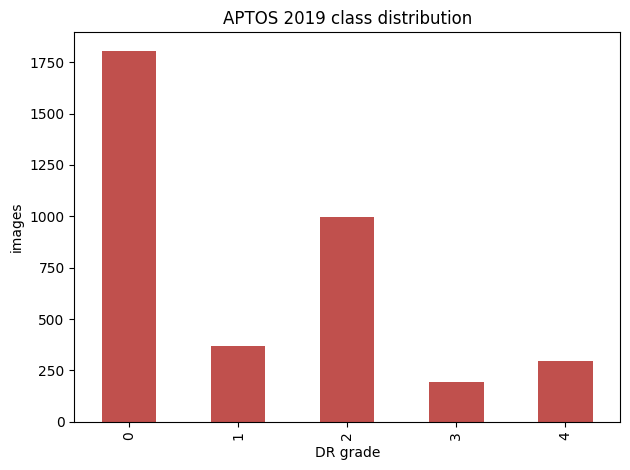

In [5]:
import pandas as pd, matplotlib.pyplot as plt
df_all = pd.read_csv('/content/aptos/train.csv')
counts = df_all['diagnosis'].value_counts().sort_index()
table = pd.DataFrame({'images': counts, 'share_%': (100 * counts / counts.sum()).round(1)})
print(table)
table.to_csv(f'{PROJECT}/results/class_distribution.csv')

counts.plot.bar(color='#c0504d'); plt.xlabel('DR grade'); plt.ylabel('images')
plt.title('APTOS 2019 class distribution'); plt.tight_layout()
plt.savefig(f'{PROJECT}/results/class_distribution.png', dpi=150); plt.show()

In [6]:
import cv2, numpy as np
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

IMG_SIZE = 64
GRADES = [0, 2, 4]          # label 0 = No DR, 1 = Moderate, 2 = Proliferative
RAW = '/content/aptos'

def preprocess(path, size=IMG_SIZE, tol=7):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    mask = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) > tol            # find the retina
    rows, cols = np.where(mask.any(1))[0], np.where(mask.any(0))[0]
    if len(rows) and len(cols):
        img = img[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]     # crop black border
    h, w = img.shape[:2]; s = max(h, w)
    sq = np.zeros((s, s, 3), np.uint8)                            # pad to square
    sq[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = img
    out = cv2.resize(sq, (size, size), interpolation=cv2.INTER_AREA)
    yy, xx = np.ogrid[:size, :size]; c = (size - 1) / 2
    out[(yy - c) ** 2 + (xx - c) ** 2 > (size / 2) ** 2] = 0       # circular mask
    return out

df = df_all[df_all['diagnosis'].isin(GRADES)].reset_index(drop=True)
paths = [f'{RAW}/train_images/{c}.png' for c in df['id_code']]
with ThreadPoolExecutor(8) as ex:
    images = np.stack(list(tqdm(ex.map(preprocess, paths), total=len(paths))))
labels = df['diagnosis'].map({g: i for i, g in enumerate(GRADES)}).to_numpy()
print(images.shape, np.bincount(labels))

  0%|          | 0/3099 [00:00<?, ?it/s]

(3099, 64, 64, 3) [1805  999  295]


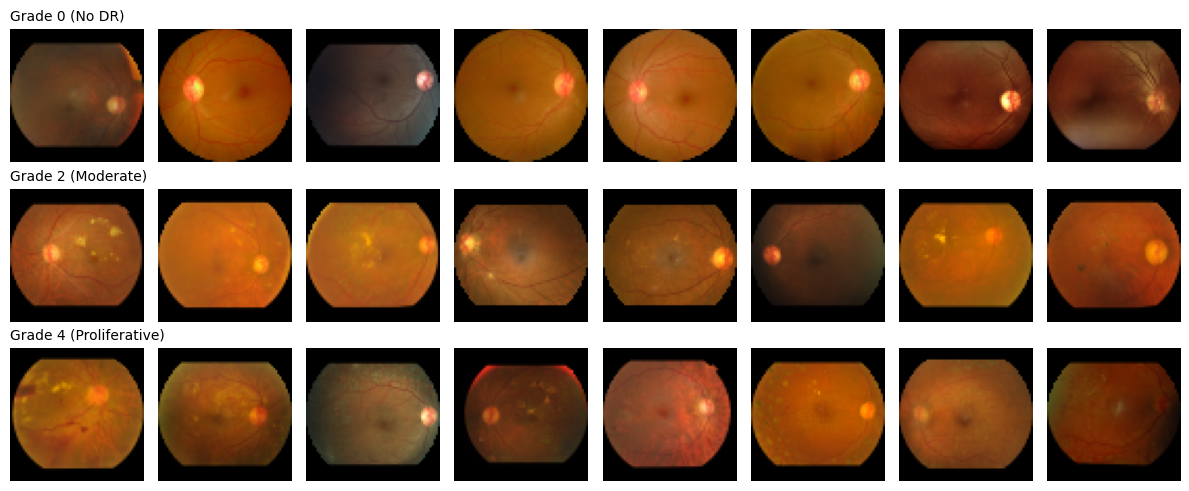

In [7]:
names = ['Grade 0 (No DR)', 'Grade 2 (Moderate)', 'Grade 4 (Proliferative)']
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
rng = np.random.default_rng(0)
for r in range(3):
    for k, i in enumerate(rng.choice(np.where(labels == r)[0], 8, replace=False)):
        axes[r, k].imshow(images[i]); axes[r, k].axis('off')
    axes[r, 0].set_title(names[r], loc='left', fontsize=10)
plt.tight_layout(); plt.savefig(f'{PROJECT}/results/real_samples.png', dpi=150); plt.show()

In [8]:
from sklearn.model_selection import train_test_split
idx = np.arange(len(df))
tr, rest = train_test_split(idx, test_size=0.30, stratify=labels, random_state=42)
va, te = train_test_split(rest, test_size=0.50, stratify=labels[rest], random_state=42)
split = np.empty(len(df), dtype=object)
split[tr], split[va], split[te] = 'train', 'val', 'test'
print(pd.crosstab(df['diagnosis'], split))

col_0      test  train  val
diagnosis                  
0           271   1263  271
2           150    699  150
4            44    207   44


similarity percentiles 50/90/99/max: [0.788 0.892 1.   ] 1.0


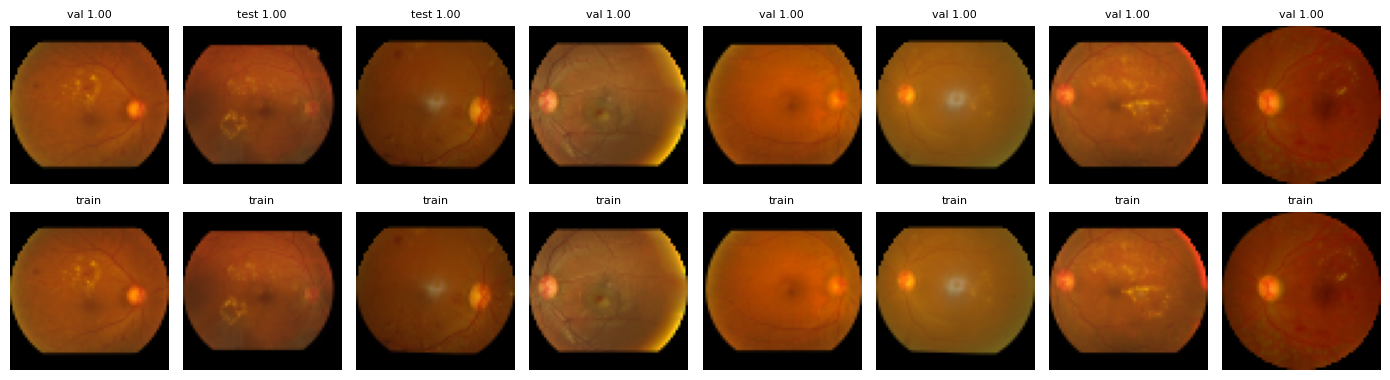

In [9]:
def detail_features(imgs):
    g = np.stack([cv2.cvtColor(i, cv2.COLOR_RGB2GRAY) for i in imgs]).astype(np.float32)
    g = g - np.stack([cv2.GaussianBlur(x, (0, 0), 4) for x in g])   # keep fine detail only
    yy, xx = np.ogrid[:IMG_SIZE, :IMG_SIZE]; c = (IMG_SIZE - 1) / 2
    f = g[:, (yy - c) ** 2 + (xx - c) ** 2 <= (0.42 * IMG_SIZE) ** 2]
    f -= f.mean(1, keepdims=True)
    return f / (np.linalg.norm(f, axis=1, keepdims=True) + 1e-8)

F = detail_features(images)
tr_idx, ev_idx = np.where(split == 'train')[0], np.where(split != 'train')[0]
sim = F[ev_idx] @ F[tr_idx].T
best, nn = sim.max(1), tr_idx[sim.argmax(1)]
print('similarity percentiles 50/90/99/max:', np.percentile(best, [50, 90, 99]).round(3), best.max().round(3))

order = np.argsort(-best)[:8]                # the 8 most similar pairs
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for k, o in enumerate(order):
    axes[0, k].imshow(images[ev_idx[o]]); axes[0, k].set_title(f'{split[ev_idx[o]]} {best[o]:.2f}', fontsize=8)
    axes[1, k].imshow(images[nn[o]]); axes[1, k].set_title('train', fontsize=8)
    axes[0, k].axis('off'); axes[1, k].axis('off')
plt.tight_layout(); plt.savefig(f'{PROJECT}/results/duplicate_check.png', dpi=150); plt.show()

In [10]:
DUP_THRESHOLD = 0.90    # adjust after looking at the grid
dups = ev_idx[best >= DUP_THRESHOLD]
split[dups] = 'excluded'
print(f'Removed {len(dups)} val/test images that duplicate a training image')
print(pd.crosstab(df['diagnosis'], split))

np.savez_compressed(f'{PROJECT}/dataset/aptos_64.npz',
                    images=images, labels=labels, grades=df['diagnosis'].to_numpy(),
                    id_codes=df['id_code'].to_numpy().astype(str), split=split.astype(str))
pd.DataFrame({'id_code': df['id_code'], 'grade': df['diagnosis'], 'label': labels,
              'split': split}).to_csv(f'{PROJECT}/dataset/splits.csv', index=False)
print(os.listdir(f'{PROJECT}/dataset'))

Removed 77 val/test images that duplicate a training image
col_0      excluded  test  train  val
diagnosis                            
0                16   264   1263  262
2                53   127    699  120
4                 8    41    207   39
['aptos_64.npz', 'splits.csv']
